# Baseline MLP — Experiment Results

> **Purpose:** Establish a baseline using a Multi-Layer Perceptron (MLP) model. Both model runs use the default random seed, `42`.

## 1. Model Configuration

| Parameter | Setting | Notes |
|:--|:--|:--|
| `--epochs` | `10` by default; extended to `80` | Used for convergence testing |
| `--lr` | `3e-4` (default) and `1e-3` (tuned) | Learning-rate comparison |
| `--num-layers` | `2` |  |
| `--hidden-dim` | `128` |  |
| Training samples | `50,000` |  |

## 2. Experimental Results

### Experiment A — Default learning rate (`--lr 3e-4`)

- **Early training:** Convergence is poor during epochs 1–10, with accuracy reaching only `0.0059` at epoch 10.
- **Convergence:** Accuracy does not become significant until approximately epoch 70.
- **Epoch 80:**

  | Metric | Result |
  |:--|--:|
  | Loss | `0.0482` |
  | Accuracy | `0.9443` (`94.43%`) |

### Experiment B — Tuned learning rate (`--lr 1e-3`)

The slightly higher learning rate performs substantially better and converges faster for the baseline model.

| Training point | Result |
|:--|:--|
| Epoch 10 | Loss: `0.4042`; accuracy: `0.4411` |
| Epoch 18 | Reaches **90%** training accuracy |
| Epoch 25 | Training accuracy saturates at approximately **96%** |

**Epoch 80 final metrics**

| Split | Loss | Accuracy |
|:--|--:|--:|
| Validation | `0.0098` | `0.9912` (`99.12%`) |
| Test | `0.0106` | `0.9870` (`98.70%`) |

### Experiment C — Full training-set evaluation (`--lr 1e-3`)

- Requires **52 or more epochs** to exceed **90%** accuracy.

**Epoch 80 final metrics**

| Split | Loss | Accuracy |
|:--|--:|--:|
| Validation | `0.0374` | `0.9703` (`97.03%`) |
| Test | `0.0482` | `0.9443` (`94.43%`) |

## 3. Model Limitations

1. **Generalization:** The model fails to generalize to unseen digit lengths.
2. **Sample efficiency:** It has poor sample efficiency and exhibits combinatorial scaling issues.
3. **Inductive bias:** Without a self-attention mechanism, the model does not capture translational or positional invariance.

## 4. Reproducibility

The experiment scripts are documented in:

- `a2/scripts/baseline_test.ipynb`
- `a2/scripts/Transformer_test.ipynb`

All parameters not specified above use their default settings. Results can be reproduced with random seed `42`.


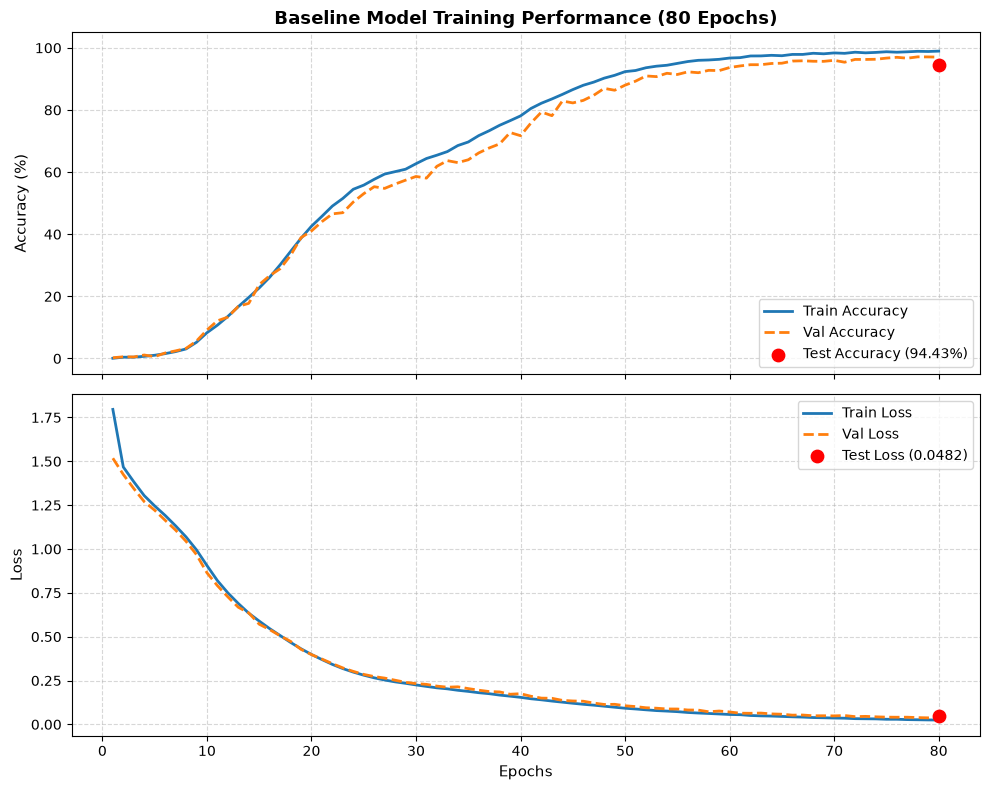

In [1]:
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Data Preparation
# ---------------------------------------------------------
epochs = list(range(1, 81))

# Training and Validation Accuracy
train_acc = [
    0.0007, 0.0041, 0.0043, 0.0069, 0.0104, 0.0156, 0.0221, 0.0307, 0.0521, 0.0829,
    0.1072, 0.1354, 0.1668, 0.1965, 0.2272, 0.2614, 0.3015, 0.3445, 0.3871, 0.4258,
    0.4577, 0.4907, 0.5153, 0.5448, 0.5581, 0.5768, 0.5937, 0.6015, 0.6093, 0.6271,
    0.6438, 0.6545, 0.6661, 0.6855, 0.6970, 0.7175, 0.7332, 0.7508, 0.7656, 0.7810,
    0.8050, 0.8219, 0.8355, 0.8502, 0.8657, 0.8796, 0.8897, 0.9025, 0.9116, 0.9235,
    0.9271, 0.9360, 0.9410, 0.9440, 0.9500, 0.9560, 0.9599, 0.9610, 0.9631, 0.9673,
    0.9685, 0.9739, 0.9741, 0.9760, 0.9747, 0.9789, 0.9789, 0.9826, 0.9809, 0.9837,
    0.9824, 0.9860, 0.9840, 0.9854, 0.9875, 0.9860, 0.9873, 0.9889, 0.9883, 0.9895
]

val_acc = [
    0.0024, 0.0054, 0.0049, 0.0112, 0.0059, 0.0176, 0.0245, 0.0325, 0.0561, 0.0917,
    0.1213, 0.1332, 0.1678, 0.1775, 0.2377, 0.2665, 0.2889, 0.3318, 0.3889, 0.4106,
    0.4406, 0.4656, 0.4694, 0.5038, 0.5306, 0.5530, 0.5476, 0.5615, 0.5740, 0.5860,
    0.5807, 0.6188, 0.6369, 0.6306, 0.6397, 0.6618, 0.6777, 0.6909, 0.7274, 0.7172,
    0.7583, 0.7934, 0.7817, 0.8289, 0.8228, 0.8309, 0.8473, 0.8696, 0.8636, 0.8799,
    0.8928, 0.9096, 0.9074, 0.9182, 0.9143, 0.9228, 0.9200, 0.9277, 0.9268, 0.9367,
    0.9418, 0.9458, 0.9458, 0.9497, 0.9506, 0.9575, 0.9584, 0.9569, 0.9566, 0.9599,
    0.9538, 0.9628, 0.9627, 0.9633, 0.9670, 0.9696, 0.9667, 0.9711, 0.9708, 0.9703
]

# Training and Validation Loss
train_loss = [
    1.7959, 1.4675, 1.3835, 1.3044, 1.2457, 1.1916, 1.1322, 1.0689, 0.9950, 0.9059,
    0.8198, 0.7499, 0.6893, 0.6340, 0.5889, 0.5460, 0.5067, 0.4674, 0.4311, 0.3987,
    0.3695, 0.3419, 0.3181, 0.2980, 0.2805, 0.2654, 0.2529, 0.2424, 0.2340, 0.2249,
    0.2165, 0.2083, 0.2026, 0.1944, 0.1880, 0.1806, 0.1749, 0.1670, 0.1608, 0.1541,
    0.1460, 0.1400, 0.1329, 0.1267, 0.1204, 0.1145, 0.1095, 0.1037, 0.0978, 0.0920,
    0.0878, 0.0830, 0.0786, 0.0757, 0.0725, 0.0678, 0.0647, 0.0621, 0.0593, 0.0564,
    0.0552, 0.0507, 0.0485, 0.0474, 0.0453, 0.0431, 0.0415, 0.0389, 0.0377, 0.0361,
    0.0352, 0.0326, 0.0319, 0.0313, 0.0291, 0.0291, 0.0272, 0.0263, 0.0253, 0.0248
]

val_loss = [
    1.5175, 1.4249, 1.3447, 1.2700, 1.2211, 1.1639, 1.1079, 1.0439, 0.9679, 0.8645,
    0.7911, 0.7271, 0.6678, 0.6355, 0.5712, 0.5403, 0.5050, 0.4732, 0.4278, 0.3978,
    0.3725, 0.3461, 0.3219, 0.3021, 0.2849, 0.2725, 0.2639, 0.2517, 0.2398, 0.2326,
    0.2281, 0.2181, 0.2120, 0.2142, 0.2040, 0.1949, 0.1871, 0.1850, 0.1718, 0.1748,
    0.1602, 0.1497, 0.1487, 0.1368, 0.1334, 0.1320, 0.1216, 0.1135, 0.1144, 0.1061,
    0.1015, 0.0947, 0.0922, 0.0878, 0.0876, 0.0820, 0.0814, 0.0717, 0.0761, 0.0707,
    0.0638, 0.0632, 0.0644, 0.0596, 0.0579, 0.0526, 0.0533, 0.0490, 0.0491, 0.0484,
    0.0504, 0.0441, 0.0456, 0.0430, 0.0412, 0.0407, 0.0409, 0.0385, 0.0372, 0.0374
]

# Metrics for Test Set
test_loss = 0.0482
test_acc = 0.9443

# Convert Accuracy to Percentage
train_acc_pct = [a * 100 for a in train_acc]
val_acc_pct = [a * 100 for a in val_acc]
test_acc_pct = test_acc * 100

# ---------------------------------------------------------
# Plotting
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Subplot 1: Accuracy Curves
ax1.plot(epochs, train_acc_pct, color='#1f77b4', linewidth=2, label='Train Accuracy')
ax1.plot(epochs, val_acc_pct, linestyle='--', color='#ff7f0e', linewidth=2, label='Val Accuracy')
ax1.scatter([80], [test_acc_pct], color='red', s=80, zorder=5, label=f'Test Accuracy ({test_acc_pct:.2f}%)')
ax1.set_title("Baseline Model Training Performance (80 Epochs)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Accuracy (%)", fontsize=11)
ax1.set_ylim(-5, 105)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right', fontsize=10)

# Subplot 2: Loss Curves
ax2.plot(epochs, train_loss, color='#1f77b4', linewidth=2, label='Train Loss')
ax2.plot(epochs, val_loss, linestyle='--', color='#ff7f0e', linewidth=2, label='Val Loss')
ax2.scatter([80], [test_loss], color='red', s=80, zorder=5, label=f'Test Loss ({test_loss})')
ax2.set_xlabel("Epochs", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

### MLP baseline — epoch-by-epoch accuracy

| Epoch | Training accuracy | Validation accuracy | Test accuracy |
|---:|---:|---:|---:|
| 1 | 0.07% | 0.24% | — |
| 2 | 0.41% | 0.54% | — |
| 3 | 0.43% | 0.49% | — |
| 4 | 0.69% | 1.12% | — |
| 5 | 1.04% | 0.59% | — |
| 6 | 1.56% | 1.76% | — |
| 7 | 2.21% | 2.45% | — |
| 8 | 3.07% | 3.25% | — |
| 9 | 5.21% | 5.61% | — |
| 10 | 8.29% | 9.17% | — |
| 11 | 10.72% | 12.13% | — |
| 12 | 13.54% | 13.32% | — |
| 13 | 16.68% | 16.78% | — |
| 14 | 19.65% | 17.75% | — |
| 15 | 22.72% | 23.77% | — |
| 16 | 26.14% | 26.65% | — |
| 17 | 30.15% | 28.89% | — |
| 18 | 34.45% | 33.18% | — |
| 19 | 38.71% | 38.89% | — |
| 20 | 42.58% | 41.06% | — |
| 21 | 45.77% | 44.06% | — |
| 22 | 49.07% | 46.56% | — |
| 23 | 51.53% | 46.94% | — |
| 24 | 54.48% | 50.38% | — |
| 25 | 55.81% | 53.06% | — |
| 26 | 57.68% | 55.30% | — |
| 27 | 59.37% | 54.76% | — |
| 28 | 60.15% | 56.15% | — |
| 29 | 60.93% | 57.40% | — |
| 30 | 62.71% | 58.60% | — |
| 31 | 64.38% | 58.07% | — |
| 32 | 65.45% | 61.88% | — |
| 33 | 66.61% | 63.69% | — |
| 34 | 68.55% | 63.06% | — |
| 35 | 69.70% | 63.97% | — |
| 36 | 71.75% | 66.18% | — |
| 37 | 73.32% | 67.77% | — |
| 38 | 75.08% | 69.09% | — |
| 39 | 76.56% | 72.74% | — |
| 40 | 78.10% | 71.72% | — |
| 41 | 80.50% | 75.83% | — |
| 42 | 82.19% | 79.34% | — |
| 43 | 83.55% | 78.17% | — |
| 44 | 85.02% | 82.89% | — |
| 45 | 86.57% | 82.28% | — |
| 46 | 87.96% | 83.09% | — |
| 47 | 88.97% | 84.73% | — |
| 48 | 90.25% | 86.96% | — |
| 49 | 91.16% | 86.36% | — |
| 50 | 92.35% | 87.99% | — |
| 51 | 92.71% | 89.28% | — |
| 52 | 93.60% | 90.96% | — |
| 53 | 94.10% | 90.74% | — |
| 54 | 94.40% | 91.82% | — |
| 55 | 95.00% | 91.43% | — |
| 56 | 95.60% | 92.28% | — |
| 57 | 95.99% | 92.00% | — |
| 58 | 96.10% | 92.77% | — |
| 59 | 96.31% | 92.68% | — |
| 60 | 96.73% | 93.67% | — |
| 61 | 96.85% | 94.18% | — |
| 62 | 97.39% | 94.58% | — |
| 63 | 97.41% | 94.58% | — |
| 64 | 97.60% | 94.97% | — |
| 65 | 97.47% | 95.06% | — |
| 66 | 97.89% | 95.75% | — |
| 67 | 97.89% | 95.84% | — |
| 68 | 98.26% | 95.69% | — |
| 69 | 98.09% | 95.66% | — |
| 70 | 98.37% | 95.99% | — |
| 71 | 98.24% | 95.38% | — |
| 72 | 98.60% | 96.28% | — |
| 73 | 98.40% | 96.27% | — |
| 74 | 98.54% | 96.33% | — |
| 75 | 98.75% | 96.70% | — |
| 76 | 98.60% | 96.96% | — |
| 77 | 98.73% | 96.67% | — |
| 78 | 98.89% | 97.11% | — |
| 79 | 98.83% | 97.08% | — |
| 80 | 98.95% | 97.03% | 94.43% |

> **Note:** Test accuracy is reported at the final checkpoint only; it is not an epoch-by-epoch test metric.

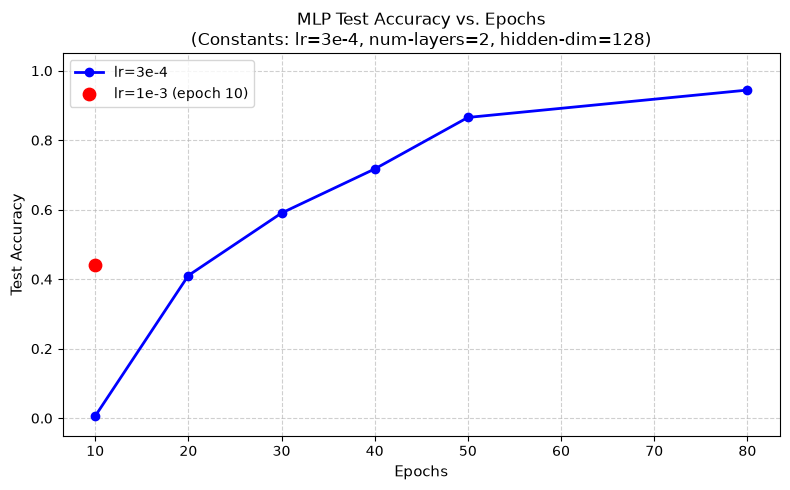

=== MLP Baseline Test Accuracy & Loss ===
      Epochs  Test Loss Test Accuracy
          10     1.3343         0.59%
          20     0.3976        41.06%
          30     0.2359        59.03%
          40     0.1748        71.72%
          50     0.1140        86.55%
          80     0.0482        94.43%
10 (lr=1e-3)     0.4042        44.11%


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# Extracted data for varying epoch sizes (with constant: lr=3e-4, num-layers=2, hidden-dim=128)
# Note: For epoch 20, the second run (loss 0.3976, acc 0.4106) is used.
epochs = [10, 20, 30, 40, 50, 80]
acc = [0.0059, 0.4106, 0.5903, 0.7172, 0.8655, 0.9443]
loss = [1.3343, 0.3976, 0.2359, 0.1748, 0.1140, 0.0482]

# Optional additional run (lr=1e-3, epochs=10)
lr_1e3_epoch = 10
lr_1e3_acc = 0.4411

constants_str = "lr=3e-4, num-layers=2, hidden-dim=128"

plt.figure(figsize=(8, 5))

# Plot primary epoch vs accuracy curve
plt.plot(epochs, acc, marker='o', color='b', linewidth=2, label="lr=3e-4")

# Plot the single data point for lr=1e-3 as a reference marker
plt.scatter([lr_1e3_epoch], [lr_1e3_acc], color='red', s=80, zorder=5, label="lr=1e-3 (epoch 10)")

plt.title(f"MLP Test Accuracy vs. Epochs\n(Constants: {constants_str})", fontsize=12)
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Test Accuracy", fontsize=11)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Baseline Accuracy Table Generation
# ---------------------------------------------------------
df_baseline = pd.DataFrame({
    'Epochs': [10, 20, 30, 40, 50, 80, '10 (lr=1e-3)'],
    'Test Loss': loss + [0.4042],
    'Test Accuracy': [f"{a * 100:.2f}%" for a in acc] + [f"{lr_1e3_acc * 100:.2f}%"]
})

print("=== MLP Baseline Test Accuracy & Loss ===")
print(df_baseline.to_string(index=False))

# Transformer — Experiment & Ablation Analysis

> **Reference configuration:** Unless a parameter is explicitly varied, the baseline Transformer uses `--ffn-dim 256`, `--nhead 4`, and `--num-layers 4`.

## 1. Hyperparameter Exploration

### Feed-forward dimension (`--ffn-dim`)

- **Best-performing value:** `256`
- Accuracy improves steadily as `ffn-dim` increases up to `256`.
- Beyond `256`, accuracy declines slightly and gradually.

### Number of attention heads (`--nhead`)

- **Best-performing value:** `4`
- Increasing `nhead` above `4` degrades performance through `nhead = 16`.
- Accuracy recovers slightly at `nhead = 32`, but remains below the peak at `nhead = 4`.

### Number of layers (`--num-layers`)

- **Best-performing value:** `4`
- Performance improves from `2` to `4` layers and then saturates.
- **Instability at 6 and 8 layers:**
  - Training loss rapidly reaches `0.0000` by epochs 8–9, leading to severe overfitting.
  - In later epochs, small weight updates trigger **gradient explosion**, destroying the trained parameters.
- **Recommended fix:** Implement **gradient clipping** to stabilize deeper configurations.
- **Compute cost:** Wall-clock training time increases substantially with depth, making `4` layers the best speed–accuracy trade-off in these tests.

## 2. Dataset Scaling & Generalization

### Sensitivity to training-set size

- **Observed threshold:** Performance degrades sharply when the number of training samples falls below approximately `20,000`.
- **Example — 5,000 training samples:**

  | Metric | Result |
  |:--|--:|
  | Loss | `1.7358` |
  | Accuracy | `0.0029` (`0.29%`) |

  More training epochs are required to approach convergence when data are scarce.

### Out-of-distribution generalization — sequence-length shift

| Architecture | Training samples | Epochs | Validation loss | Validation accuracy | Test loss | Test accuracy |
|:--|--:|--:|--:|--:|--:|--:|
| **MLP baseline** | 50,000 | 10 | 0.0344 | 98.90% | 28.4665 | 1.12% |
| **Transformer** | 20,000 | 10 | 0.0006 | 100.00% | 31.7834 | 0.00% |

> **Key observation:** Both architectures fail to generalize to out-of-distribution sequence dimensions. This is accompanied by a catastrophic increase in test loss and near-zero test accuracy.

## 3. Transformer vs. MLP Baseline

| Aspect | Observation |
|:--|:--|
| **Sample efficiency** | A tuned Transformer trained on **20,000 samples** outperforms the MLP baseline trained on **50,000 or more samples** after the same number of epochs. |
| **Convergence speed** | The Transformer reaches `100%` validation accuracy with 20,000 samples in 10 epochs. The MLP requires a substantially larger training set to reach comparable performance. |
| **Compute efficiency** | The Transformer has higher per-epoch latency, but its faster convergence in fewer epochs offsets this overhead in the reported experiments. |

## 4. Key Engineering Takeaways

| Area | Recommendation / finding |
|:--|:--|
| **Architecture** | Use `--ffn-dim 256`, `--nhead 4`, and `--num-layers 4`. |
| **Optimization stability** | Enable **gradient clipping** to mitigate gradient explosion in deeper models (`num-layers >= 6`). |
| **Training-set size** | Maintain at least **20,000 samples** to avoid the observed optimization failure at smaller sizes. |
| **Generalization** | Neither model generalizes across varying input dimensions without explicit length-extrapolation or inductive mechanisms. |


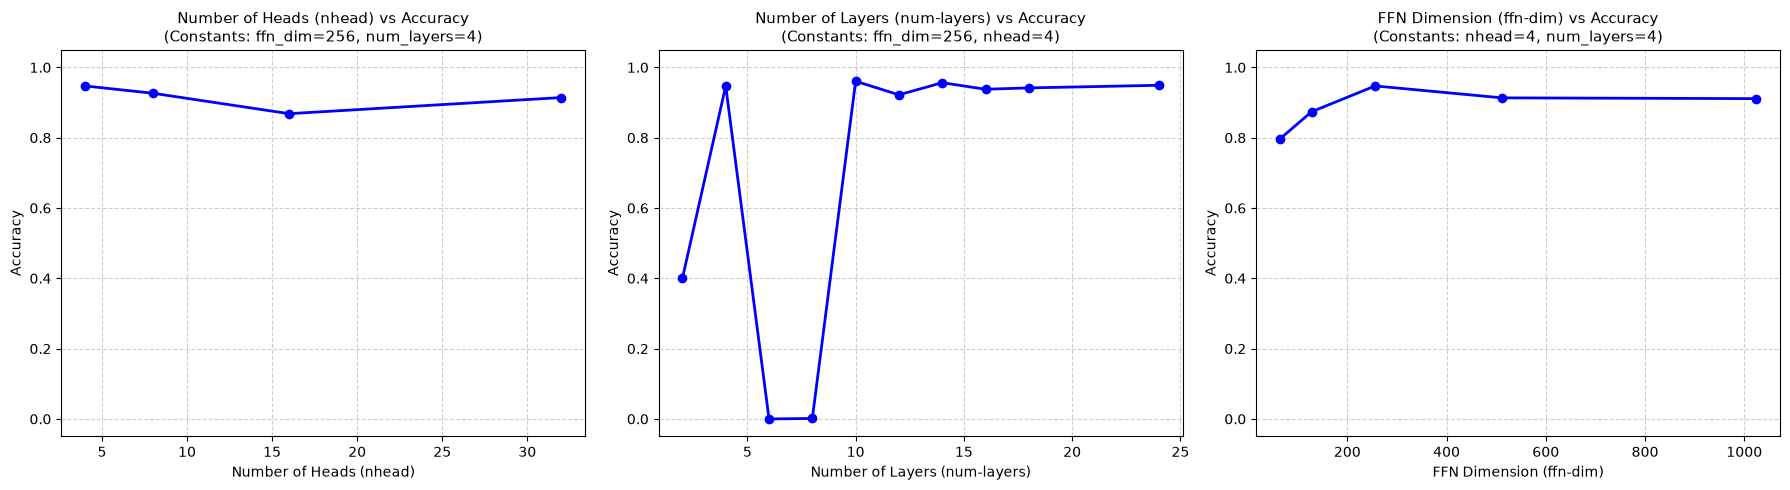

In [3]:
import matplotlib.pyplot as plt

# Data definitions
data_nhead = {
    "constants": {"ffn_dim": 256, "num_layers": 4},
    "x": [4, 8, 16, 32],
    "acc": [0.9472, 0.9264, 0.8683, 0.9142],
    "xlabel": "Number of Heads (nhead)"
}

data_num_layers = {
    "constants": {"ffn_dim": 256, "nhead": 4},
    "x": [2, 4, 6, 8, 10, 12, 14, 16, 18, 24],
    "acc": [0.3998, 0.9472, 0.0000, 0.0013, 0.9606, 0.9219, 0.9564, 0.9378, 0.9416, 0.9491],
    "xlabel": "Number of Layers (num-layers)"
}

data_ffn_dim = {
    "constants": {"nhead": 4, "num_layers": 4},
    "x": [64, 128, 256, 512, 1024],
    "acc": [0.7964, 0.8738, 0.9472, 0.9133, 0.9111],
    "xlabel": "FFN Dimension (ffn-dim)"
}

dataset = [data_nhead, data_num_layers, data_ffn_dim]

# Plotting 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, d in zip(axes, dataset):
    # Construct title string from constants
    const_str = ", ".join([f"{k}={v}" for k, v in d["constants"].items()])
    
    ax.plot(d["x"], d["acc"], marker='o', color='b', linewidth=2)
    ax.set_title(f"{d['xlabel']} vs Accuracy\n(Constants: {const_str})", fontsize=11)
    ax.set_xlabel(d["xlabel"], fontsize=10)
    ax.set_ylabel("Accuracy", fontsize=10)
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [4]:
import pandas as pd

# ---------------------------------------------------------
# 1. Transformer Experiments Data
# ---------------------------------------------------------

# Set 1: Varying nhead (Constants: ffn_dim=256, num_layers=4)
df_nhead = pd.DataFrame({
    '--nhead': [4, 8, 16, 32],
    'Test Loss': [0.0446, 0.0644, 0.1063, 0.0682],
    'Test Accuracy': ['94.72%', '92.64%', '86.83%', '91.42%']
})

# Set 2: Varying num-layers (Constants: ffn_dim=256, nhead=4)
df_num_layers = pd.DataFrame({
    '--num-layers': [2, 4, 6, 8, 10, 12, 14, 16, 18, 24],
    'Test Loss': [0.4437, 0.0446, 4.7074, 8.0414, 0.0314, 0.0626, 0.0361, 0.0488, 0.0449, 0.0408],
    'Test Accuracy': [
        '39.98%', '94.72%', '0.00%', '0.13%', 
        '96.06%', '92.19%', '95.64%', '93.78%', 
        '94.16%', '94.91%'
    ]
})

# Set 3: Varying ffn-dim (Constants: nhead=4, num_layers=4)
df_ffn_dim = pd.DataFrame({
    '--ffn-dim': [64, 128, 256, 512, 1024],
    'Test Loss': [0.1685, 0.0955, 0.0446, 0.0694, 0.0814],
    'Test Accuracy': ['79.64%', '87.38%', '94.72%', '91.33%', '91.11%']
})

# ---------------------------------------------------------
# 2. MLP Experiments Data
# ---------------------------------------------------------

# Constants: num_layers=2, hidden_dim=128
df_mlp = pd.DataFrame({
    '--epochs': [10, 10, '20 (Run 1)', '20 (Run 2)', 30, 40, 50, 80],
    '--lr': ['3e-4', '1e-3', '3e-4', '3e-4', '3e-4', '3e-4', '3e-4', '3e-4'],
    'Test Loss': [1.3343, 0.4042, 1.1636, 0.3976, 0.2359, 0.1748, 0.1140, 0.0482],
    'Test Accuracy': [
        '0.59%', '44.11%', '1.87%', '41.06%', 
        '59.03%', '71.72%', '86.55%', '94.43%'
    ]
})

# ---------------------------------------------------------
# Display Tables
# ---------------------------------------------------------

print("=== TRANSFORMER: Varying nhead (ffn-dim=256, num-layers=4) ===")
print(df_nhead.to_string(index=False))

print("\n=== TRANSFORMER: Varying num-layers (ffn-dim=256, nhead=4) ===")
print(df_num_layers.to_string(index=False))

print("\n=== TRANSFORMER: Varying ffn-dim (nhead=4, num-layers=4) ===")
print(df_ffn_dim.to_string(index=False))

print("\n=== MLP: Varying Epochs & LR (num-layers=2, hidden-dim=128) ===")
print(df_mlp.to_string(index=False))

=== TRANSFORMER: Varying nhead (ffn-dim=256, num-layers=4) ===
 --nhead  Test Loss Test Accuracy
       4     0.0446        94.72%
       8     0.0644        92.64%
      16     0.1063        86.83%
      32     0.0682        91.42%

=== TRANSFORMER: Varying num-layers (ffn-dim=256, nhead=4) ===
 --num-layers  Test Loss Test Accuracy
            2     0.4437        39.98%
            4     0.0446        94.72%
            6     4.7074         0.00%
            8     8.0414         0.13%
           10     0.0314        96.06%
           12     0.0626        92.19%
           14     0.0361        95.64%
           16     0.0488        93.78%
           18     0.0449        94.16%
           24     0.0408        94.91%

=== TRANSFORMER: Varying ffn-dim (nhead=4, num-layers=4) ===
 --ffn-dim  Test Loss Test Accuracy
        64     0.1685        79.64%
       128     0.0955        87.38%
       256     0.0446        94.72%
       512     0.0694        91.33%
      1024     0.0814        91.

## Training Curve — Transformer Baseline Configuration

The following training curve uses the baseline Transformer configuration below. All other parameters retain their default values.

| Parameter | Value |
|:--|:--|
| `--ffn-dim` | `256` |
| `--nhead` | `4` |
| `--num-layers` | `4` |
| `epochs` | `20` |


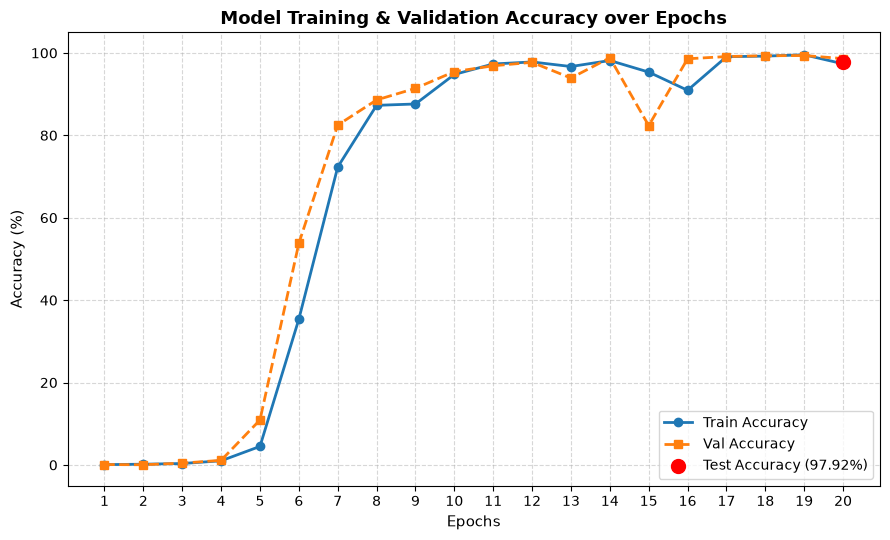

In [5]:
import matplotlib.pyplot as plt


epochs = list(range(1, 21))
train_acc = [0.0008, 0.0018, 0.0035, 0.0101, 0.0450, 0.3539, 0.7230, 0.8728, 0.8761, 0.9478, 0.9732, 0.9781, 0.9670, 0.9816, 0.9535, 0.9093, 0.9908, 0.9923, 0.9955, 0.9736]
val_acc = [0.0010, 0.0005, 0.0044, 0.0112, 0.1092, 0.5380, 0.8249, 0.8859, 0.9141, 0.9547, 0.9688, 0.9772, 0.9390, 0.9883, 0.8236, 0.9858, 0.9912, 0.9932, 0.9937, 0.9863]


train_acc_pct = [a * 100 for a in train_acc]
val_acc_pct = [a * 100 for a in val_acc]
test_acc_pct = 97.92

plt.figure(figsize=(9, 5.5))


plt.plot(epochs, train_acc_pct, marker='o', color='#1f77b4', linewidth=2, label='Train Accuracy')
plt.plot(epochs, val_acc_pct, marker='s', linestyle='--', color='#ff7f0e', linewidth=2, label='Val Accuracy')


plt.scatter([20], [test_acc_pct], color='red', s=100, zorder=5, label=f'Test Accuracy ({test_acc_pct}%)')


plt.title("Model Training & Validation Accuracy over Epochs", fontsize=13, fontweight='bold')
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Accuracy (%)", fontsize=11)
plt.xticks(epochs)
plt.ylim(-5, 105)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

### Transformer baseline — epoch-by-epoch accuracy

| Epoch | Training accuracy | Validation accuracy | Test accuracy |
|---:|---:|---:|---:|
| 1 | 0.08% | 0.10% | — |
| 2 | 0.18% | 0.05% | — |
| 3 | 0.35% | 0.44% | — |
| 4 | 1.01% | 1.12% | — |
| 5 | 4.50% | 10.92% | — |
| 6 | 35.39% | 53.80% | — |
| 7 | 72.30% | 82.49% | — |
| 8 | 87.28% | 88.59% | — |
| 9 | 87.61% | 91.41% | — |
| 10 | 94.78% | 95.47% | — |
| 11 | 97.32% | 96.88% | — |
| 12 | 97.81% | 97.72% | — |
| 13 | 96.70% | 93.90% | — |
| 14 | 98.16% | 98.83% | — |
| 15 | 95.35% | 82.36% | — |
| 16 | 90.93% | 98.58% | — |
| 17 | 99.08% | 99.12% | — |
| 18 | 99.23% | 99.32% | — |
| 19 | 99.55% | 99.37% | — |
| 20 | 97.36% | 98.63% | 97.92% |

> **Note:** Test accuracy is reported at the final checkpoint only; it is not an epoch-by-epoch test metric.